# Авито · По каким объявлениям состоялась сделка?

Считаем сделкой продажу покупателю, который нашёл продавца через Авито. Момент оценки — после закрытия объявления и получения доступного ответа на опрос. Результат — бинарная разметка каждого объявления и оценка доли сделок в семи категориях.

Запустите **Run All** из каталога, где находится папка `data/`. Нужны Python 3.10+, pandas, NumPy, scikit-learn (1.3+), matplotlib и ядро Jupyter. Последняя ячейка записывает `submission.csv` в текущий каталог. Все признаки рассчитываются локально. Codex использовался для написания кода и пояснений. Тексты сообщений обрабатываются воспроизводимыми правилами, обращений к языковой модели при запуске нет.

In [1]:
from pathlib import Path
import re
from io import BytesIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, train_test_split
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score
from threadpoolctl import threadpool_limits

SEED = 42
DATA = Path("data")
date_cols = {"listings": ["published_at", "closed_at"], "events": ["event_time"],
             "messages": ["sent_at"], "surveys": ["answered_at"], "verified": []}
raw = {name: pd.read_csv(DATA / f"{name}.csv", parse_dates=dates or None)
       for name, dates in date_cols.items()}
source_ids = raw["listings"].listing_id
rows = []
for name, df in raw.items():
    na = df.isna().sum()
    rows.append({"Файл": name, "Строк": len(df), "Объявлений": df.listing_id.nunique(),
                 "Полных повторов": df.duplicated().sum(),
                 "Чужих ключей": (~df.listing_id.isin(source_ids)).sum(),
                 "Пропуски по полям": ", ".join(f"{k} {v}" for k, v in na[na > 0].items()) or "—"})
display(pd.DataFrame(rows).set_index("Файл"))
l, e, m, s, v = [raw[k].drop_duplicates().copy() for k in date_cols]
assert l.listing_id.is_unique and v.listing_id.is_unique and s.listing_id.is_unique
assert v.is_deal.isin([0, 1]).all() and v.listing_id.isin(l.listing_id).all()
l = l.set_index("listing_id").sort_index()
truth = v.set_index("listing_id").is_deal.sort_index()

,Строк,Объявлений,Полных повторов,Чужих ключей,Пропуски по полям
Файл,,,,,
listings,15457,15274,183,0,"category 388, description_length 462"
events,183242,14789,1814,0,"user_id 3016, new_price 180226"
messages,352209,13805,0,0,text 1409
surveys,6061,5942,119,0,—
verified,300,300,0,0,—


## 1. Приведение карточек и журналов к одной шкале времени

Для строк с обратным интервалом проверяем, лежат ли события между переставленными границами. После исправления используем только события и сообщения в период жизни карточки. Опрос приходит после закрытия, поэтому для него проверяем тип продавца, способ снятия и время ответа отдельно. Пустой идентификатор покупателя у изменения цены и пустая новая цена у действий покупателя соответствуют схеме событий.

In [2]:
bounds = ["published_at", "closed_at"]
inverted = l.published_at > l.closed_at
l.loc[inverted, bounds] = l.loc[inverted, bounds[::-1]].to_numpy()
print("Обратных интервалов:", int(inverted.sum()))
def restrict_to_lifetime(log, time_col):
    joined = log.join(l[bounds], on="listing_id", validate="many_to_one")
    ok = joined[time_col].between(joined.published_at, joined.closed_at)
    changed = joined.listing_id.isin(l.index[inverted])
    print(f"{time_col}: внутри исправленных границ {int((changed & ok).sum())}/{int(changed.sum())}, "
          f"исключено вне интервала или без карточки {int((~ok).sum())}")
    return joined.loc[ok, log.columns].copy()

e = restrict_to_lifetime(e, "event_time")
m = restrict_to_lifetime(m, "sent_at")
survey = s.join(l[["seller_type", "close_type", "closed_at"]], on="listing_id")
eligible = (survey.seller_type.eq("private") & survey.close_type.eq("снято продавцом")
            & survey.answered_at.ge(survey.closed_at))
print("Ответов вне условий опроса:", int((~eligible).sum()))
survey = survey.loc[eligible].set_index("listing_id")
answer = survey.answer.reindex(l.index)

cities_before = l.region.nunique()
l["region"] = (l.region.str.strip().str.lower().str.replace(r"^г\.\s*", "", regex=True)
               .replace({"moscow": "москва", "спб": "санкт-петербург", "питер": "санкт-петербург",
                         "санкт петербург": "санкт-петербург", "екб": "екатеринбург",
                         "н. новгород": "нижний новгород"}))
invalid_price = l.price.le(1) | l.price.ge(99_999_999)
print(f"Вариантов города {cities_before} → {l.region.nunique()}. "
      f"Нулевых, единичных или аномально больших стартовых цен: {invalid_price.sum()}. "
      f"Пропусков в поле длины описания: {l.description_length.isna().sum()}.")
print("Расхождений со схемой событий:",
      int((e.user_id.isna() != e.event_type.eq("price_change")).sum()),
      "по покупателю,", int((e.new_price.notna() != e.event_type.eq("price_change")).sum()), "по цене.")

Обратных интервалов: 40
event_time: внутри исправленных границ 557/557, исключено вне интервала или без карточки 28
sent_at: внутри исправленных границ 1155/1158, исключено вне интервала или без карточки 450
Ответов вне условий опроса: 0
Вариантов города 28 → 8. Нулевых, единичных или аномально больших стартовых цен: 183. Пропусков в поле длины описания: 458.
Расхождений со схемой событий: 0 по покупателю, 0 по цене.


### Восстановление категории по товару

В этой выгрузке заголовки повторяются. Сначала ищем тот же заголовок среди карточек с известной категорией, затем используем первые два слова. При неоднозначности требуем согласия хотя бы 90% примеров. Проверяем метод, временно скрыв категорию у пятой части известных карточек. Цены-заглушки исключаем из расчёта скидки. Длину описания и город для разметки не используем.

In [3]:
title = l.title.fillna("").str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
product = title.str.split().str[:2].str.join(" ")
def infer_categories(reference, targets):
    result = pd.Series(index=targets, dtype="object")
    for key in (title, product):
        counts = pd.crosstab(key.loc[reference], l.loc[reference, "category"])
        reliable = counts.max(axis=1).div(counts.sum(axis=1)).ge(0.90)
        result = result.fillna(key.loc[targets].map(counts.loc[reliable].idxmax(axis=1)))
    return result

known = l.index[l.category.notna()]
ref, masked = train_test_split(known, test_size=0.2, stratify=l.loc[known, "category"], random_state=SEED)
test_cat = infer_categories(ref, masked)
print(f"На скрытых категориях правильно {test_cat.eq(l.loc[masked, 'category']).sum()}/{len(masked)}, "
      f"покрытие {test_cat.notna().mean():.1%}.")
missing = l.index[l.category.isna()]
category = l.category.fillna(infer_categories(known, missing)).fillna("Категория неизвестна")
print(f"Восстановлено категорий: {category.loc[missing].ne('Категория неизвестна').sum()}/{len(missing)}.")
display(category.value_counts().rename("Объявлений").to_frame())

На скрытых категориях правильно 2979/2979, покрытие 100.0%.
Восстановлено категорий: 381/381.


,Объявлений
category,
Электроника,3379
Одежда и обувь,3297
Детские товары,2116
Мебель и интерьер,1940
Запчасти и аксессуары,1608
Бытовая техника,1576
Спорт и отдых,1358


## 2. Что видно в переписке и по телефону

Единица наблюдения в чате — разговор с **одним** покупателем. Различаем интерес, договорённость, прибытие и благодарность после встречи. Если покупатель отказался или перенёс встречу после договорённости, снимаем положительный сигнал этого разговора. Другой покупатель всё ещё мог забрать товар. Ответ продавца «уже продано» учитываем отдельно, поскольку канал продажи неизвестен.

Нормализуем регистр, пунктуацию и числа. Для частых фраз исправляем единичную перестановку соседних символов, только если восстановление однозначно. Пустое сообщение сохраняет факт контакта.

In [4]:
def normalize_text(series):
    return (series.fillna("").str.lower().str.replace("ё", "е")
            .str.replace(r"\d+", "0", regex=True).str.replace(r"[^а-яa-z0 ]+", " ", regex=True)
            .str.replace(r"\s+", " ", regex=True).str.strip())

words = normalize_text(m.text)
counts = words.value_counts()
repairs = {}
for phrase in counts[counts >= 100].index:
    for i in range(len(phrase) - 1):
        typo = phrase[:i] + phrase[i:i+2][::-1] + phrase[i+2:]
        if typo != phrase and 0 < counts.get(typo, 0) < counts[phrase] / 8:
            repairs[typo] = phrase if repairs.get(typo, phrase) == phrase else None
fixed = words.map(repairs).fillna(words)
print("Пустых сообщений:", m.text.isna().sum(), "· Исправлено перестановок:", words.ne(fixed).sum())
patterns = {
    "intent": ("buyer", r"^беру$|забираю|договорились|отложите для меня"),
    "plan": ("buyer", r"скиньте адрес|куда подъехать|во сколько удобно|могу подъехать|оплачу переводом"),
    "enroute": ("buyer", r"^еду|выезжаю|уже подхожу|через 0 минут буду|опаздываю"),
    "arrival": ("buyer", r"подъехал|на месте"),
    "comes_out": ("seller", r"выхожу|спускаюсь|сейчас выйду"),
    "thanks": ("buyer", r"^спасибо$|спасибо все отлично|все супер спасибо"),
    "cancel": ("buyer", r"передумал|не приеду|не смогу|не подошло|не возьму|перенес|перенести|в другой день"),
    "sold_reply": ("seller", r"уже продал|продано|уже нет извините"),
}
keys = ["listing_id", "chat_id"]
times = {}
for name, (role, pattern) in patterns.items():
    hit = m.author.eq(role) & fixed.str.contains(pattern, regex=True)
    times[name] = m.loc[hit].groupby(keys).sent_at.max()
chat = m.groupby(keys).agg(chat_len=("author", "size"), roles=("author", "nunique"))
times = pd.DataFrame(times).reindex(chat.index)
active = ["intent", "plan", "enroute", "arrival", "comes_out", "thanks"]
for name in active:
    chat[name] = times[name].notna() & (times.cancel.isna() | times[name].gt(times.cancel))
chat["met"] = chat.arrival & chat.comes_out
chat["after_thanks"] = chat.thanks & (chat.plan | chat.intent | chat.enroute | chat.arrival)
chat["lost"] = times.cancel.notna()
chat["sold_reply"] = times.sold_reply.notna()
chat["two_sided"] = chat.roles.eq(2)
signals = active + ["met", "after_thanks", "lost", "sold_reply", "two_sided"]
by_listing = chat.groupby(level="listing_id")
flags = by_listing[signals].max().reindex(l.index, fill_value=False)
f = flags.astype(float)
f["longest_chat"] = by_listing.chat_len.max().reindex(l.index, fill_value=0)
f["n_chats"] = by_listing.size().reindex(l.index, fill_value=0)
f["n_dialogues"] = by_listing.two_sided.sum().reindex(l.index, fill_value=0)
f["n_canceled"] = by_listing.lost.sum().reindex(l.index, fill_value=0)

Пустых сообщений: 1405 · Исправлено перестановок: 14714


In [5]:
phone = e.loc[e.event_type.eq("phone_view")]
phone_g = phone.groupby("listing_id")
f["n_phone"] = phone_g.size().reindex(l.index, fill_value=0)
f["phone_users"] = phone_g.user_id.nunique().reindex(l.index, fill_value=0)
f["phone_repeats"] = f.n_phone - f.phone_users
f["life_days"] = (l.closed_at - l.published_at).dt.total_seconds() / 86400
f["hours_after_phone"] = (l.closed_at - phone_g.event_time.max()).dt.total_seconds() / 3600
f["hours_after_chat"] = (l.closed_at - m.groupby("listing_id").sent_at.max()).dt.total_seconds() / 3600
f["views"] = l.views_total
f["favorites"] = e.loc[e.event_type.eq("favorite")].groupby("listing_id").size().reindex(l.index, fill_value=0)
f["contacts_per_view"] = (f.n_chats + f.n_phone) / (1 + f.views)
f["discount"] = (1 - l.current_price / l.price.where(~invalid_price)).where(l.current_price.gt(1)).clip(-1, 1)
f["price_relative"] = l.price.where(~invalid_price)
f["price_relative"] /= f.price_relative.groupby(category).transform("median")
f["n_price_changes"] = e.loc[e.event_type.eq("price_change")].groupby("listing_id").size().reindex(l.index, fill_value=0)
print("Расхождения счётчиков после очистки:",
      int(f.n_phone.ne(l.phone_views_total).sum()), "по показам телефона,",
      int(f.n_chats.ne(l.chats_total).sum()), "по числу чатов.")
print("На опрос ответили", int(answer.notna().sum()), "из",
      int((l.seller_type.eq("private") & l.close_type.eq("снято продавцом")).sum()),
      "частных продавцов, снявших объявление.")

Расхождения счётчиков после очистки: 5 по показам телефона, 20 по числу чатов.
На опрос ответили 5942 из 9651 частных продавцов, снявших объявление.


## 3. От наблюдений к разметке

Используем два уровня. Первый обучается на ответах продавцов и ищет сочетания поведенческих сигналов, характерные для продажи. «Другая причина» неоднозначна, поэтому её пропускаем при обучении этого уровня. Градиентный бустинг с неглубокими деревьями может различать, например, короткий чат с отказом и длинный с подтверждением встречи. Этот уровень строится только по поведению, без текста ответа на опрос. Каждая карточка получает прогноз модели, обученной на других продавцах. Из слабого обучения целиком исключаем продавцов проверенной выборки.

Второй уровень обучаем на проверенных сделках. Логистическая регрессия с регуляризацией объединяет поведенческий прогноз, ответ продавца, тип закрытия и несколько понятных сигналов. Так шумный опрос остаётся одним из свидетельств. Показы телефона помогают учесть сделки, по которым переписка оборвалась. Блокировку трактуем как отсутствие сделки по определению кейса.

In [6]:
weak_target = answer.map({"Продал на Авито": 1, "Продал в другом месте": 0,
                          "Передумал продавать": 0})
seller = l.seller_id
can_train = weak_target.notna() & ~seller.isin(seller.loc[truth.index])
weak = pd.Series(index=l.index, dtype=float)
for train, hold in GroupKFold(n_splits=5).split(f, groups=seller):
    ids = l.index[train]
    fit_ids = ids[can_train.loc[ids].to_numpy()]
    model = HistGradientBoostingClassifier(max_iter=100, max_leaf_nodes=9,
                min_samples_leaf=35, learning_rate=0.06, l2_regularization=3,
                early_stopping=False, random_state=SEED)
    with threadpool_limits(limits=1):
        model.fit(f.loc[fit_ids], weak_target.loc[fit_ids])
        weak.iloc[hold] = model.predict_proba(f.iloc[hold])[:, 1]
assert weak.between(0, 1).all()

X = pd.DataFrame(index=l.index)
X["behavior_log_odds"] = np.log(weak / (1 - weak))
for name in ["arrival", "enroute", "after_thanks", "lost", "sold_reply"]:
    X[name] = f[name]
X["log_phone"] = np.log1p(f.n_phone)
X["phone_only"] = f.n_phone.gt(0) & ~flags.two_sided
X["no_contact"] = f.n_phone.eq(0) & f.n_chats.eq(0) & l.phone_views_total.eq(0) & l.chats_total.eq(0)
X["manually_closed"] = l.close_type.eq("снято продавцом")
X["business"] = l.seller_type.eq("business")
for name, value in {"survey_avito": "Продал на Авито", "survey_elsewhere": "Продал в другом месте",
                    "survey_changed_mind": "Передумал продавать"}.items():
    X[name] = answer.eq(value)
X = X.astype(float)
blocked = l.close_type.eq("заблокировано")
def fit_verified(ids):
    model = LogisticRegression(C=1, max_iter=1000)
    return model.fit(X.loc[ids], truth.loc[ids])

def probabilities(model, ids):
    result = pd.Series(model.predict_proba(X.loc[ids])[:, 1], index=ids)
    return result.mask(blocked.loc[ids], 0.0)

# Жёсткий порог 0.5 может занизить число тихих продаж. Для каждой категории
# ожидаемое число сделок равно сумме вероятностей. Столько же карточек
# с наибольшими оценками помечаем единицей. При равенстве решает listing_id.
def label_by_category(prob):
    labels = pd.Series(0, index=prob.index, dtype="int64")
    for _, group in prob.sort_index().groupby(category.loc[prob.index]):
        k = int(np.floor(group.sum() + 0.5))
        labels.loc[group.nlargest(k, keep="first").index] = 1
    return labels

## 4. Проверка на 300 объявлениях

Делим проверенные объявления на пять частей с учётом класса и продавца. Каждый раз четыре части обучают регрессию. Для пятой части применяем правило долей вместе со всеми непроверенными объявлениями, как при сдаче. Правильных ответов этих объявлений модель не видит. Параметры и правило перевода вероятности в класс фиксированы. Для сравнения берём простую разметку по положительному опросу и порог 0,5 у той же модели.

**Точность** — доля настоящих сделок среди найденных, **полнота** — доля найденных среди настоящих, **F1** — их гармоническое среднее. **CatShareMAE** — средняя по категориям абсолютная ошибка долей, здесь выражена в процентных пунктах. У объявлений без исходной категории при проверке доступна только восстановленная.

In [7]:
unknown = l.index.difference(truth.index)
oof = pd.DataFrame(index=truth.index, columns=["p", "label", "fold"], dtype=float)
folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
for fold, (train, test) in enumerate(folds.split(truth, truth, groups=seller.loc[truth.index]), 1):
    tr, te = truth.index[train], truth.index[test]
    assert not set(seller.loc[tr]).intersection(seller.loc[te])
    p = probabilities(fit_verified(tr), unknown.union(te))
    oof.loc[te, "p"] = p.loc[te]
    oof.loc[te, "label"] = label_by_category(p).loc[te]
    oof.loc[te, "fold"] = fold
assert oof.notna().all().all()
pred = oof.label.astype(int)

def measures(y, yhat):
    shares = (yhat - y).groupby(category.loc[y.index]).mean()
    return {"Точность": precision_score(y, yhat, zero_division=0),
            "Полнота": recall_score(y, yhat, zero_division=0), "F1": f1_score(y, yhat, zero_division=0),
            "CatShareMAE, п.п.": 100 * shares.abs().mean()}

strategies = {"Только ответ «Продал на Авито»": X.loc[truth.index, "survey_avito"].astype(int),
              "Модель, порог 0,5": oof.p.ge(.5).astype(int), "Модель, по долям": pred}
display(pd.DataFrame({k: measures(truth, val) for k, val in strategies.items()}).T.round(3))
matrix = confusion_matrix(truth, pred, labels=[0, 1])
display(pd.DataFrame(matrix, index=["Факт: нет", "Факт: сделка"], columns=["Прогноз: нет", "Прогноз: сделка"]))
compare = pd.DataFrame({"Факт": truth, "Прогноз": pred, "Категория": category.loc[truth.index]})
check = compare.groupby("Категория").agg(n=("Факт","size"), fact=("Факт","mean"), forecast=("Прогноз","mean"))
check["Отклонение, п.п."] = 100 * (check.forecast - check.fact)
display(check.rename(columns={"fact":"Доля по проверке", "forecast":"Доля по модели"}).round(3))
print("F1 по отдельным блокам:", [round(f1_score(truth.loc[g.index], pred.loc[g.index]), 2)
                                    for _, g in oof.groupby("fold")])
delta = check["Отклонение, п.п."]
worst = delta.abs().idxmax()
print(f"Наибольшее расхождение на проверке у категории «{worst}»: {delta[worst]:+.1f} п.п. "
      f"В группе {int(check.loc[worst, 'n'])} объявлений.")

,Точность,Полнота,F1,"CatShareMAE, п.п."
Только ответ «Продал на Авито»,0.792,0.362,0.497,20.076
"Модель, порог 0,5",0.849,0.776,0.811,6.354
"Модель, по долям",0.807,0.793,0.800,6.796


,Прогноз: нет,Прогноз: сделка
Факт: нет,162,22
Факт: сделка,24,92


,n,Доля по проверке,Доля по модели,"Отклонение, п.п."
Категория,,,,
Бытовая техника,30,0.400,0.467,6.667
Детские товары,45,0.489,0.467,-2.222
Запчасти и аксессуары,35,0.314,0.343,2.857
Мебель и интерьер,35,0.457,0.371,-8.571
Одежда и обувь,63,0.270,0.254,-1.587
Спорт и отдых,28,0.250,0.429,17.857
Электроника,64,0.484,0.406,-7.812


F1 по отдельным блокам: [0.84, 0.84, 0.78, 0.74, 0.79]
Наибольшее расхождение на проверке у категории «Спорт и отдых»: +17.9 п.п. В группе 28 объявлений.


### Надёжность сигналов и разбор ошибок

Для каждого сигнала сравниваем частоту сделки при его наличии и отсутствии на открытой проверке. Строки могут пересекаться. По каналам контакта отдельно считаем ложные сделки и пропуски. Примеры ошибок выбираем по близости к границе уверенности и показываем вместе с наблюдаемыми признаками.

In [8]:
evidence = {"Покупатель прибыл": flags.arrival, "Поблагодарил после договорённости": flags.after_thanks,
            "Есть отмена хотя бы в одном чате": flags.lost,
            "Продавец сообщил о продаже в чате": flags.sold_reply,
            "Телефон открыт, двустороннего чата нет": X.phone_only.eq(1),
            "Продавец выбрал продажу на Авито": X.survey_avito.eq(1),
            "Объявление истекло": l.close_type.eq("истёк срок")}
stats = []
for name, indicator in evidence.items():
    mask = indicator.loc[truth.index]
    stats.append([name, int(mask.sum()), truth[mask].mean(), truth[~mask].mean()])
display(pd.DataFrame(stats, columns=["Сигнал", "С сигналом, шт.", "Доля с сигналом",
                                     "Доля без сигнала"]).set_index("Сигнал").round(3))
channel = pd.Series(np.select([flags.two_sided, f.n_phone.gt(0), f.n_chats.gt(0)],
                              ["Диалог", "Телефон без диалога", "Односторонний чат"],
                              default="Нет контактов в логах"), index=l.index)
errors = pd.DataFrame({"Канал": channel.loc[truth.index], "Факт": truth, "Прогноз": pred,
                       "Ложные сделки": pred.gt(truth), "Пропуски": pred.lt(truth),
                       "Оценка": oof.p, "Опрос": answer.loc[truth.index].fillna("—"),
                       "Прибыл": flags.arrival.loc[truth.index], "Отмена": flags.lost.loc[truth.index]})
display(errors.groupby("Канал").agg(n=("Факт", "size"), **{
    "Ложные сделки": ("Ложные сделки", "sum"), "Пропуски": ("Пропуски", "sum")}))
wrong = errors.loc[pred.ne(truth)].copy()
wrong["До 0,5"] = (wrong["Оценка"] - .5).abs()
examples = pd.concat([wrong[wrong["Факт"].eq(k)].nsmallest(3, "До 0,5") for k in [0, 1]])
display(examples.drop(columns=["Ложные сделки", "Пропуски", "До 0,5"]).round(2))
for col in ["Ложные сделки", "Пропуски"]:
    by_channel = errors.groupby("Канал")[col].sum()
    print(f"{col}: {int(by_channel.sum())}, из них {int(by_channel.max())} в группе «{by_channel.idxmax()}».")
print("Доля сделок на проверке:", f"{truth.mean():.1%}", "· доля ответивших на опрос:",
      f"{answer.loc[truth.index].notna().mean():.1%} на проверке и {answer.notna().mean():.1%} во всей выгрузке.")

,"С сигналом, шт.",Доля с сигналом,Доля без сигнала
Сигнал,,,
Покупатель прибыл,60,0.917,0.254
Поблагодарил после договорённости,22,1.000,0.338
Есть отмена хотя бы в одном чате,35,0.371,0.389
Продавец сообщил о продаже в чате,38,0.526,0.366
"Телефон открыт, двустороннего чата нет",14,0.500,0.381
Продавец выбрал продажу на Авито,53,0.792,0.300
Объявление истекло,106,0.255,0.459


,n,Ложные сделки,Пропуски
Канал,,,
Диалог,265,18,21
Нет контактов в логах,16,0,0
Односторонний чат,5,0,0
Телефон без диалога,14,4,3


,Канал,Факт,Прогноз,Оценка,Опрос,Прибыл,Отмена
listing_id,,,,,,,
133712,Диалог,0,1,0.50,—,False,False
121649,Телефон без диалога,0,1,0.48,Другая причина,False,False
160585,Диалог,0,1,0.53,Передумал продавать,False,False
114975,Диалог,1,0,0.41,Продал в другом месте,False,True
137939,Диалог,1,0,0.41,Продал в другом месте,False,False
154049,Диалог,1,0,0.37,Другая причина,False,False


Ложные сделки: 22, из них 18 в группе «Диалог».
Пропуски: 24, из них 21 в группе «Диалог».
Доля сделок на проверке: 38.7% · доля ответивших на опрос: 38.3% на проверке и 38.9% во всей выгрузке.


В чате «я подъехал» фиксирует встречу, но покупатель может отказаться после осмотра. Показ телефона фиксирует открытие номера, содержание разговора неизвестно. Это два источника неопределённости при интерпретации ошибок. Небольшое число проверенных карточек внутри категории делает её долю чувствительной к единичным ошибкам. Итоговая закрытая оценка может отличаться.

На этой проверке порог 0,5 немного лучше по обеим метрикам. В итоговом файле используем заранее выбранное правило по сумме вероятностей, чтобы число положительных меток соответствовало оценённому числу продаж в каждой категории. Это зависит от калибровки модели. Наибольшую ошибку на открытой выборке видим в категории «Спорт и отдых» — модель дала 12 сделок среди 28 объявлений, проверка подтвердила 7. Для этой категории особенно полезно увеличить объём ручной проверки, прежде чем делать выводы о динамике продаж.

## 5. Сколько сделок приходится на каждую категорию

Переобучаем регрессию на всех проверенных объявлениях. Для них в итоговой разметке сохраняем известный исход, для остальных используем прогноз. Знаменатель доли — все уникальные объявления категории, включая истёкшие и заблокированные. Соседние столбцы помогают отделить различия в активности покупателей от различий в видимости контактов.

,Объявлений,Сделок,"Сделки, %","Диалог, %","Телефон без диалога, %","Ответ на опрос, %","Нет контактов, %"
Категория,,,,,,,
Детские товары,2116,953,45.0,90.4,2.3,40.0,4.5
Электроника,3379,1510,44.7,91.9,2.2,39.0,3.7
Бытовая техника,1576,606,38.5,86.2,6.3,42.9,5.3
Мебель и интерьер,1940,679,35.0,83.2,5.7,37.7,8.0
Спорт и отдых,1358,468,34.5,85.9,3.8,36.4,7.3
Одежда и обувь,3297,1100,33.4,87.0,1.8,38.4,8.0
Запчасти и аксессуары,1608,458,28.5,70.5,16.9,38.1,10.6


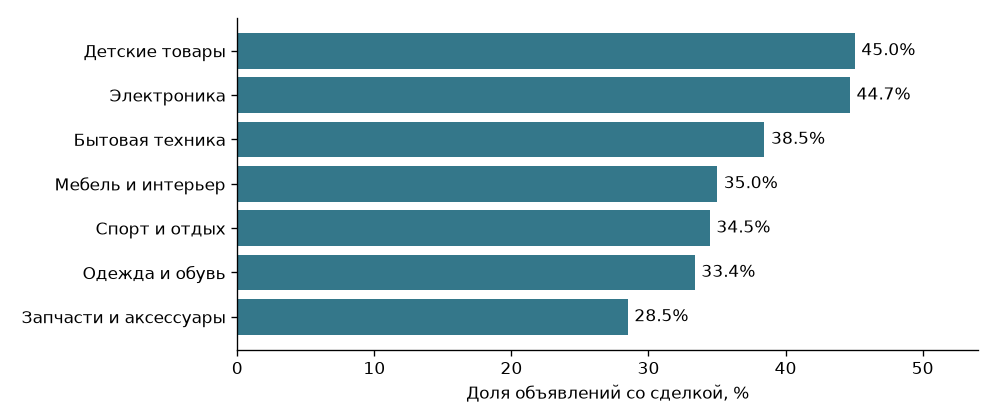

Наибольшая оценка доли у категории «Детские товары» (45.0%), наименьшая — «Запчасти и аксессуары» (28.5%). Разрыв 16.6 п.п.
В категории «Запчасти и аксессуары» в 16.9% карточек открыли телефон без двустороннего чата. Здесь стоит проверить оценку независимым опросом покупателей.
В категории «Запчасти и аксессуары» 10.6% карточек без контакта. Для неё стоит проверить в эксперименте, увеличивают ли улучшения карточки долю первых обращений.
Всего оценено сделок: 5,774 из 15,274 (37.8%).


In [9]:
final_model = fit_verified(truth.index)
estimated = label_by_category(probabilities(final_model, unknown))
deals = pd.concat([estimated, truth]).sort_index().astype(int).rename("is_deal")
report = pd.DataFrame({"Категория": category, "Сделка": deals, "Телефон без диалога": X.phone_only,
                       "Есть диалог": flags.two_sided, "Есть ответ на опрос": answer.notna(),
                       "Нет контактов": X.no_contact})
summary = report.groupby("Категория").agg(
    Объявлений=("Сделка", "size"), Сделок=("Сделка", "sum"),
    **{"Сделки, %": ("Сделка", "mean"), "Диалог, %": ("Есть диалог", "mean"),
       "Телефон без диалога, %": ("Телефон без диалога", "mean"),
       "Ответ на опрос, %": ("Есть ответ на опрос", "mean"), "Нет контактов, %": ("Нет контактов", "mean")})
percent_cols = summary.columns[2:]
summary[percent_cols] *= 100
summary = summary.sort_values("Сделки, %", ascending=False)
display(summary.round(1))
fig, ax = plt.subplots(figsize=(8.3, 3.5))
bars = ax.barh(summary.index, summary["Сделки, %"], color="#34778a")
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.set(xlabel="Доля объявлений со сделкой, %", xlim=(0, summary["Сделки, %"].max() + 9))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
buf = BytesIO()
fig.savefig(buf, format="png", dpi=120)
plt.close(fig)
display(Image(data=buf.getvalue()))

rate = summary["Сделки, %"]
quiet = summary["Телефон без диалога, %"].idxmax()
priority = summary["Нет контактов, %"].idxmax()
print(f"Наибольшая оценка доли у категории «{rate.idxmax()}» ({rate.max():.1f}%), "
      f"наименьшая — «{rate.idxmin()}» ({rate.min():.1f}%). Разрыв {rate.max()-rate.min():.1f} п.п.")
print(f"В категории «{quiet}» в {summary.loc[quiet, 'Телефон без диалога, %']:.1f}% карточек открыли "
      "телефон без двустороннего чата. Здесь стоит проверить оценку независимым опросом покупателей.")
print(f"В категории «{priority}» {summary.loc[priority, 'Нет контактов, %']:.1f}% карточек без контакта. "
      "Для неё стоит проверить в эксперименте, увеличивают ли улучшения карточки долю первых обращений.")
print(f"Всего оценено сделок: {deals.sum():,} из {len(deals):,} ({deals.mean():.1%}).")

## 6. Файл для автопроверки

Сохраняем только идентификатор и бинарный исход. Повторно читаем файл и сверяем с исходной выгрузкой состав объявлений, формат и значения.

In [10]:
submission = deals.rename_axis("listing_id").reset_index()
output_path = Path("submission.csv")
submission.to_csv(output_path, index=False, lineterminator="\n")
saved = pd.read_csv(output_path)
assert list(saved.columns) == ["listing_id", "is_deal"]
assert saved.listing_id.is_unique and set(saved.listing_id) == set(source_ids)
assert saved.is_deal.isin([0, 1]).all()
pd.testing.assert_frame_equal(saved, submission)
print(f"{output_path.name}: {len(saved):,} строк, формат проверен.")

submission.csv: 15,274 строк, формат проверен.
